# igPC applied to Van der Pol data — Tutorial

This notebook shows how to apply the igPC identification method to a signal
produced either by the **full stochastic Van der Pol oscillator** (simulated
on the fly) or by an **uploaded experimental signal** (measured pressure
time-series from a real thermoacoustic rig).

The preprocessing pipeline is identical in both cases:
raw pressure signal → band-pass filter → Hilbert transform → amplitude envelope A(t).

---
**Outline**
0. Configuration — choose source and solver options  
1. Load or simulate the signal  
2. Envelope extraction (band-pass + Hilbert)  
3. Mean-square displacement and diffusion coefficient *c*  
4. Two-level correction for non-Gaussian envelopes  
5. Parameter identification via Eqs. 10–11  
6. Summary and comparison

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

# ooigpc modules
from ooigpc.solvers.van_der_pol import simulate_van_der_pol, amplitude_envelope
from ooigpc.signal import bandpass_butter, hilbert_envelope
from ooigpc.diffusion import compute_msd, fit_msd
from ooigpc.correction import apply_correction
from ooigpc.igpc import identify

plt.rcParams.update({'font.size': 12, 'figure.dpi': 120})

---
## 0 — Configuration

Edit the cells below to select the signal source and solver settings.
Everything downstream adapts automatically.

In [19]:
# ── Signal source ──────────────────────────────────────────────────────────────
# 'simulate' : generate the Van der Pol signal on the fly
# 'upload'   : load an experimental CSV or .npy file  (see cell below)
SOURCE = 'upload'

# ── Physical / system parameters ──────────────────────────────────────────────
# These are used for the simulation and for the theoretical reference lines.
# When SOURCE = 'upload', set omega, dt_sim and (optionally) the true params.
omega      = 2 * np.pi * 120   # ω₀ = 2π × f₀  (rad/s)
f0         = omega / (2*np.pi) # fundamental frequency (Hz)
nu_true    = 16.0              # linear growth rate ν  (s⁻¹)
kappa_true = 3.4               # nonlinear coefficient κ
Gamma_true = 1e7               # noise intensity Γ  (Pa²·s⁻³)
c_true     = Gamma_true / (4 * omega**2)   # true diffusion coeff

# ── Simulation settings (ignored when SOURCE = 'upload') ──────────────────────
NOISE  = 'white'   # 'white' : symplectic Euler + i.i.d. white noise  (fast, good amplitude statistics)
                   # 'ou'    : Heun + calibrated OU noise              (matches original paper MATLAB solver)
SEED   = 0         # random seed
N      = 2_000_000 # number of time steps  (paper: 6e6 → T = 300 s; 2e6 → T = 100 s)
dt_sim = 5e-5      # time step Δt (s)

# OU noise settings (only used when NOISE = 'ou')
TC_OU  = 5e-4      # OU correlation time τ_c (s)      — paper: 5e-4
BW_HZ  = 50.0      # band-pass HALF-bandwidth (Hz)    — paper: ±50 Hz
                   # BW_HZ is also used for the Hilbert filter (all cases)

# ── Band-pass filter settings (all sources) ────────────────────────────────────
# Rule of thumb: BW_HZ ≥ 3·ν so amplitude sidebands fit in the band.
# For f₀ = 120 Hz, ν = 16 s⁻¹ → BW_HZ ≥ 48 Hz; paper uses BW_HZ = 50 Hz.
if NOISE == 'white':
    BW_HZ = 100.0   # use 50 Hz for white noise too (good default)

print(f"SOURCE  : {SOURCE}")
print(f"NOISE   : {NOISE}  (only for 'simulate')")
print(f"f₀      : {f0:.1f} Hz")
print(f"BW_HZ   : ±{BW_HZ:.0f} Hz  (band-pass half-bandwidth)")
if SOURCE == 'simulate':
    T_total = N * dt_sim
    print(f"N, dt   : {N:.2g},  {dt_sim:.0e} s  →  T = {T_total:.0f} s")
    print(f"A_eq    : {np.sqrt(8*nu_true/kappa_true):.4f}  (= √(8ν/κ))")
    print(f"c_true  : {c_true:.6f}")

SOURCE  : upload
NOISE   : white  (only for 'simulate')
f₀      : 120.0 Hz
BW_HZ   : ±100 Hz  (band-pass half-bandwidth)


---
## 1 — Load or simulate the signal

### 1a — Upload experimental data  *(only when `SOURCE = 'upload'`)*

Supported formats:

| Format | Expected content |
|--------|------------------|
| `.csv` | One column = η(t) in Pa, or two columns = [t, η]. Header row optional. |
| `.npy` | 1-D array η(t) in Pa. |
| `.npz` | Keys `eta` and (optionally) `t`. |

Set `dt_upload` to the sampling interval of your signal (seconds).
The notebook will band-pass filter and extract the Hilbert envelope automatically.

In [20]:
if SOURCE == 'upload':     
    import pathlib

    # ── Edit these two lines ───────────────────────────────────────────────────
    FILE_PATH = '../matlab/my_signal.csv'   # path to your data file
    dt_sim    = 5e-5              # sampling interval of YOUR signal (s)
    # ──────────────────────────────────────────────────────────────────────────

    p = pathlib.Path(FILE_PATH)
    ext = p.suffix.lower()

    if ext == '.csv':
        raw = np.loadtxt(p, delimiter=',', comments='#')
        eta = raw[:, -1].astype(float)   # last column = signal
    elif ext == '.npy':
        eta = np.load(p).ravel().astype(float)
    elif ext == '.npz':
        data = np.load(p)
        eta  = data['eta'].ravel().astype(float)
        if 't' in data:
            dt_sim = float(data['t'][1] - data['t'][0])
    else:
        raise ValueError(f"Unsupported file extension: {ext!r}")

    fs   = 1.0 / dt_sim
    time = np.arange(len(eta)) * dt_sim
    print(f"Loaded  : {p.name}")
    print(f"Samples : {len(eta):,}  →  T = {len(eta)*dt_sim:.1f} s")
    print(f"fs      : {fs:.0f} Hz")
    print(f"η range : [{eta.min():.3g}, {eta.max():.3g}]")
else:
    print("SOURCE = 'simulate' — skipping upload cell.")

Loaded  : my_signal.csv
Samples : 6,000,001  →  T = 300.0 s
fs      : 20000 Hz
η range : [-7.57, 7.51]


### 1b — Simulate the Van der Pol ODE  *(only when `SOURCE = 'simulate'`)*

The stochastic Van der Pol equation (Eq. 2):

$$
\ddot{\eta} - 2\nu\,\dot{\eta} + \kappa\,\eta^2\,\dot{\eta} + \omega_0^2\,\eta = \Xi(t)
$$

**White noise** (`NOISE = 'white'`): symplectic Euler + i.i.d. Gaussian noise.  
Fast (~30 s for N = 2×10⁶).  Amplitude error < 0.1 %.

**OU noise** (`NOISE = 'ou'`): Heun (RK2) + calibrated Ornstein-Uhlenbeck noise.  
Matches the original paper MATLAB solver exactly.  ~3× slower.

In [21]:
if SOURCE == 'simulate':
    fs = 1.0 / dt_sim

    if NOISE == 'white':
        print(f"Simulating VdP — symplectic Euler + white noise (seed={SEED}) ...")
        time, eta, eta_dot = simulate_van_der_pol(
            nu=nu_true, kappa=kappa_true, Gamma=Gamma_true, omega=omega,
            N=N, dt=dt_sim, seed=SEED,
            method='symplectic', noise_type='white',
        )

    elif NOISE == 'ou':
        print(f"Simulating VdP — Heun + calibrated OU noise (seed={SEED}) ...")
        time, eta, eta_dot = simulate_van_der_pol(
            nu=nu_true, kappa=kappa_true, Gamma=Gamma_true, omega=omega,
            N=N, dt=dt_sim, seed=SEED,
            method='heun', noise_type='ou',
            tau_c=TC_OU, bandwidth_hz=2*BW_HZ,   # full BW for OU calibration
        )

    else:
        raise ValueError(f"Unknown NOISE: {NOISE!r}. Choose 'white' or 'ou'.")

    print(f"  Done.  duration = {N*dt_sim:.0f} s   ({N*dt_sim*f0:.0f} oscillation cycles)")
    print(f"  eta range : [{eta.min():.3g}, {eta.max():.3g}]")

else:
    print("SOURCE = 'upload' — skipping simulation cell.")

SOURCE = 'upload' — skipping simulation cell.


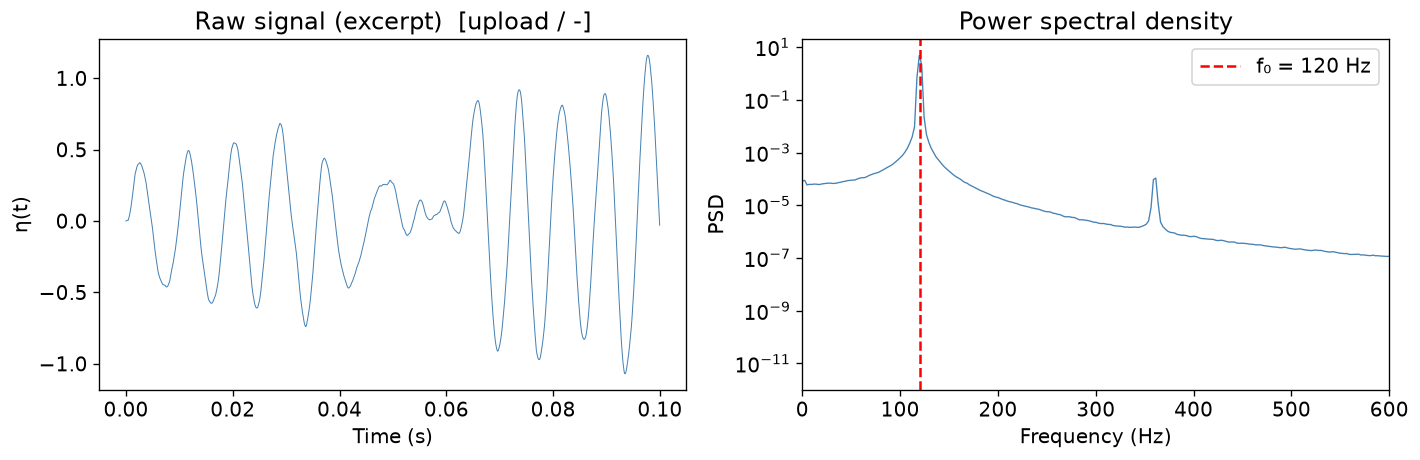

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Short excerpt
n_show = min(int(0.1 / dt_sim), len(eta))
t_show = np.arange(n_show) * dt_sim
axes[0].plot(t_show, eta[:n_show], lw=0.6, color='steelblue')
axes[0].set(xlabel='Time (s)', ylabel='η(t)',
            title=f'Raw signal (excerpt)  [{SOURCE} / {NOISE if SOURCE=="simulate" else "-"}]')

# PSD
freqs, psd = welch(eta, fs=1/dt_sim, nperseg=8192)
axes[1].semilogy(freqs, psd, lw=0.8, color='steelblue')
axes[1].axvline(f0, color='r', ls='--', lw=1.5, label=f'f₀ = {f0:.0f} Hz')
axes[1].set(xlabel='Frequency (Hz)', ylabel='PSD',
            title='Power spectral density', xlim=[0, min(600, 1/(2*dt_sim))])
axes[1].legend()

plt.tight_layout()
plt.show()

---
## 2 — Envelope extraction: band-pass + Hilbert

The **Hilbert amplitude envelope** is the practical workflow for both
measured and simulated data:
1. Band-pass filter η(t) around $f_0 \pm \Delta f$ to isolate the thermoacoustic mode
2. Hilbert transform → analytic signal → envelope $A_H(t) = |\eta_a(t)|$

**Bandwidth rule**: use $\Delta f \geq 3\nu$ so the amplitude relaxation
sidebands fit inside the passband.  Too narrow → sub-cycle ripple in $A_H$
→ spurious peak in MSD/(2τ) → *c* overestimated.

Band-pass filter: 20.0 – 220.0 Hz  (Butterworth, order 4)
Hilbert envelope extraction ...
  mean(A_H) [after transient] = 6.1151
  A_eq = √(8ν/κ)             = 6.1357


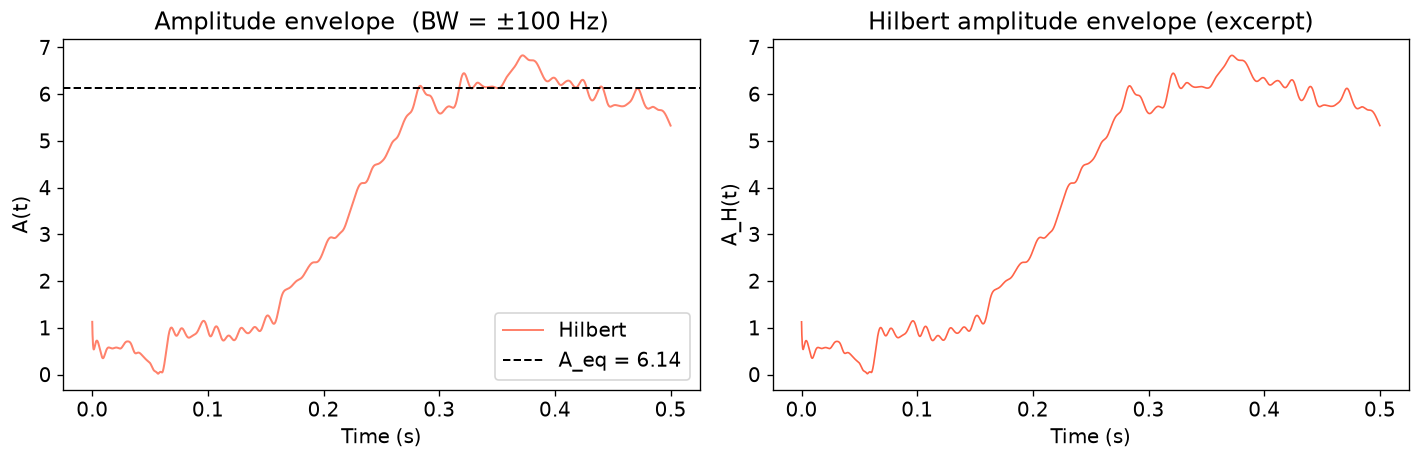

In [23]:
fs = 1.0 / dt_sim
f_low  = f0 - BW_HZ
f_high = f0 + BW_HZ

print(f"Band-pass filter: {f_low:.1f} – {f_high:.1f} Hz  (Butterworth, order 4)")
eta_bp = bandpass_butter(eta, fs=fs, f_low=f_low, f_high=f_high, order=4)

print("Hilbert envelope extraction ...")
A_hil = hilbert_envelope(eta_bp)

A_eq = np.sqrt(8 * nu_true / kappa_true)
print(f"  mean(A_H) [after transient] = {A_hil[5001:].mean():.4f}")
print(f"  A_eq = √(8ν/κ)             = {A_eq:.4f}")

# ── State-space envelope for comparison (simulation only) ──────────────────────
if SOURCE == 'simulate':
    A_ref = amplitude_envelope(eta, eta_dot, omega)

# ── Plots ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
n_cmp = min(int(0.5 / dt_sim), len(A_hil))
t_cmp = np.arange(n_cmp) * dt_sim

if SOURCE == 'simulate':
    axes[0].plot(t_cmp, A_ref[:n_cmp], lw=1.2, label='State-space (ref)', color='steelblue')

axes[0].plot(t_cmp, A_hil[:n_cmp], lw=1.2, label='Hilbert', color='tomato', alpha=0.8)
axes[0].axhline(A_eq, color='k', ls='--', lw=1.2, label=f'A_eq = {A_eq:.2f}')
axes[0].set(xlabel='Time (s)', ylabel='A(t)',
            title=f'Amplitude envelope  (BW = ±{BW_HZ:.0f} Hz)')
axes[0].legend()

if SOURCE == 'simulate':
    i0 = 5000
    axes[1].scatter(A_ref[i0::50], A_hil[i0::50], s=1, alpha=0.3, color='steelblue')
    lim = [0, max(A_ref[i0:].max(), A_hil[i0:].max()) * 1.05]
    axes[1].plot(lim, lim, 'r--', lw=1.5, label='ideal')
    axes[1].set(xlabel='A_ref (state-space)', ylabel='A_Hilbert',
                title='Scatter: state-space vs. Hilbert',
                xlim=lim, ylim=lim, aspect='equal')
    axes[1].legend()
else:
    axes[1].plot(t_cmp, A_hil[:n_cmp], color='tomato', lw=1.0)
    axes[1].set(xlabel='Time (s)', ylabel='A_H(t)',
                title='Hilbert amplitude envelope (excerpt)')

plt.tight_layout()
plt.show()

---
## 3 — Mean-square displacement and diffusion coefficient *c*

MSD model (Eq. 40):
$$\text{MSD}_{\text{mod}}(\tau) = 2\,C(0)\,[1 - e^{-\lambda\tau}]$$

Diffusion coefficient (Eq. 14):
$$c = C(0)\cdot\lambda$$

C(0)    = 0.2669
λ       = 32.1302 s⁻¹
c_est   = 4.288338


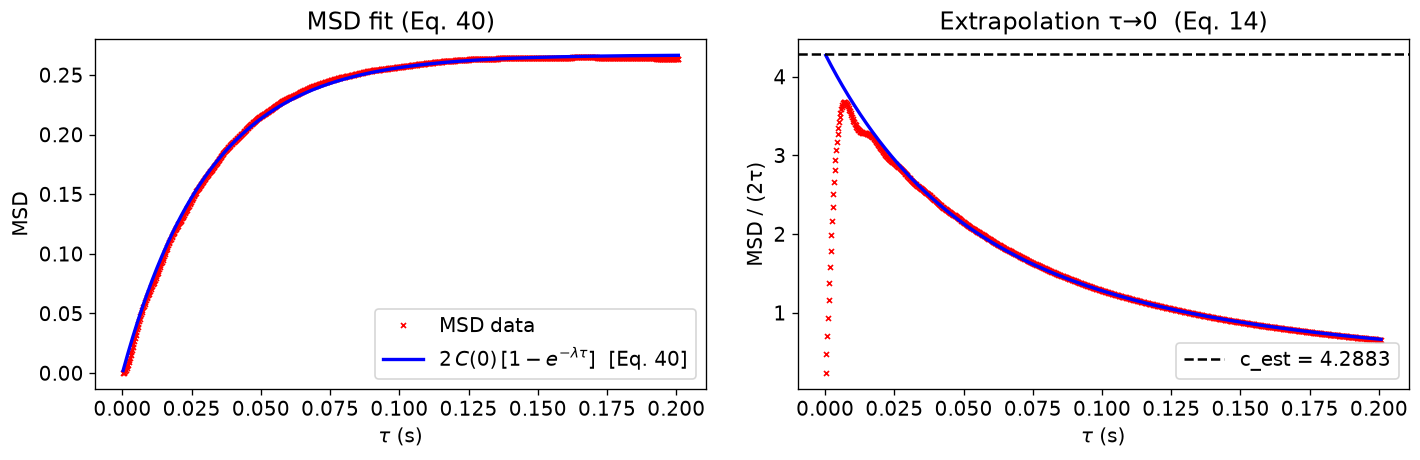

In [24]:
tau_values = np.arange(2.5e-4, 0.201, 2.5e-4)

taus, msd = compute_msd(A_hil, tau_values, dt_sim=dt_sim)
A_hat, T_hat, msd_fit = fit_msd(taus, msd)
c_recov = A_hat / (2 * T_hat)

print(f"C(0)    = {A_hat:.4f}")
print(f"λ       = {1/T_hat:.4f} s⁻¹")
print(f"c_est   = {c_recov:.6f}")
if SOURCE == 'simulate':
    print(f"c_true  = {c_true:.6f}   error = {abs(c_recov-c_true)/c_true*100:.1f} %")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(taus, msd, 'rx', ms=3, label='MSD data')
axes[0].plot(taus, msd_fit, 'b-', lw=2,
             label=r'$2\,C(0)\,[1-e^{-\lambda\tau}]$  [Eq. 40]')
axes[0].set(xlabel=r'$\tau$ (s)', ylabel='MSD', title='MSD fit (Eq. 40)')
axes[0].legend()

axes[1].plot(taus, msd / (2*taus), 'rx', ms=3)
axes[1].plot(taus, msd_fit / (2*taus), 'b-', lw=2)
axes[1].axhline(c_recov, color='k', ls='--', label=f'c_est = {c_recov:.4f}')
if SOURCE == 'simulate':
    axes[1].axhline(c_true,  color='r', ls=':',  label=f'c_true = {c_true:.4f}')
axes[1].set(xlabel=r'$\tau$ (s)', ylabel='MSD / (2τ)',
            title='Extrapolation τ→0  (Eq. 14)')
axes[1].legend()

plt.tight_layout()
plt.show()

---
## 4 — Two-level correction for non-Gaussian envelopes

Region 1 (marginally stable): Eqs. 30–31 and 33.  
Region 2 (linearly unstable): Eq. 20.

μ             = 6.1151
std_raw       = 0.3653
σ (corrected) = 0.3621
Region        = 2  (linearly unstable)


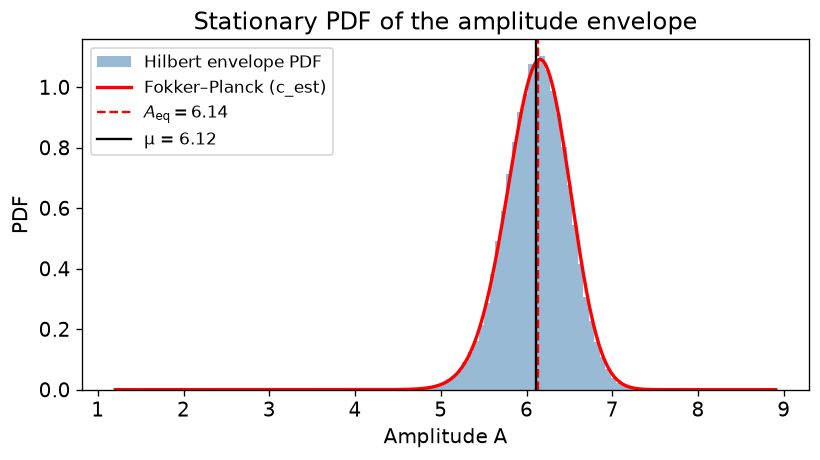

In [25]:
amp_positive = A_hil[5000:][A_hil[5000:] > 0]
corr = apply_correction(amp_positive)

print(f"μ             = {corr.mu:.4f}")
print(f"std_raw       = {corr.std_raw:.4f}")
print(f"σ (corrected) = {corr.sigma:.4f}")
print(f"Region        = {corr.region}  "
      f"({'marginally stable' if corr.region==1 else 'linearly unstable'})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(amp_positive, bins=120, density=True, alpha=0.55,
        color='steelblue', label='Hilbert envelope PDF')

# Fokker–Planck overlay (uses true params if simulating, recovered c otherwise)
a_fp = nu_true;  b_fp = kappa_true / 8.0
c_fp = c_true if SOURCE == 'simulate' else c_recov
A_grid = np.linspace(amp_positive.min(), amp_positive.max(), 800)
log_p  = np.log(A_grid) + a_fp * A_grid**2 / (2 * c_fp) - b_fp * A_grid**4 / (4 * c_fp)
log_p -= log_p.max()
p_fp   = np.exp(log_p)
from scipy.integrate import trapezoid
p_fp  /= trapezoid(p_fp, A_grid)
fp_label = 'Fokker–Planck (true params)' if SOURCE == 'simulate' else 'Fokker–Planck (c_est)'
ax.plot(A_grid, p_fp, 'r-', lw=2, label=fp_label)

A_eq = np.sqrt(8 * nu_true / kappa_true)
ax.axvline(A_eq,    color='r', ls='--', lw=1.4,
           label=f'$A_{{\\rm eq}}={A_eq:.2f}$')
ax.axvline(corr.mu, color='k', ls='-',  lw=1.4,
           label=f'μ = {corr.mu:.2f}')
ax.set(xlabel='Amplitude A', ylabel='PDF', title='Stationary PDF of the amplitude envelope')
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

---
## 5 — Parameter identification (Eqs. 10–11)

$$
\nu = \frac{9\sigma^4 + 2\mu^2\sigma^2 - \mu^4}{2\mu^2\sigma^2(\sigma^2 - \mu^2)} \cdot c
\tag{10}
$$

$$
\frac{\kappa}{8} = \frac{3\sigma^2 - \mu^2}{2\mu^2\sigma^2(\sigma^2 - \mu^2)} \cdot c
\tag{11}
$$

In [26]:
ident = identify(amp_positive, c=c_recov, omega=omega)

print("Identified parameters:")
if SOURCE == 'simulate':
    err_nu    = (ident.nu    - nu_true)    / abs(nu_true)    * 100
    err_kappa = (ident.kappa - kappa_true) / abs(kappa_true) * 100
    err_Gamma = (ident.Gamma - Gamma_true) / abs(Gamma_true) * 100
    print(f"  ν     = {ident.nu:.2f}  s⁻¹   (true: {nu_true:.1f},   error: {err_nu:+.1f} %)")
    print(f"  κ     = {ident.kappa:.3f}        (true: {kappa_true:.2f},  error: {err_kappa:+.1f} %)")
    print(f"  Γ     = {ident.Gamma:.3e}  (true: {Gamma_true:.1e}, error: {err_Gamma:+.1f} %)")
else:
    print(f"  ν     = {ident.nu:.2f}  s⁻¹")
    print(f"  κ     = {ident.kappa:.3f}")
    print(f"  Γ     = {ident.Gamma:.3e}")
print(f"  c_est = {c_recov:.6f}")

Identified parameters:
  ν     = 16.29  s⁻¹
  κ     = 3.473
  Γ     = 9.751e+06
  c_est = 4.288338


---
## 6 — Summary and comparison

In [27]:
# ── State-space reference (simulation only) ────────────────────────────────────
if SOURCE == 'simulate':
    from ooigpc.diffusion import compute_msd, fit_msd
    from ooigpc.igpc import identify

    A_ref_pos = A_ref[5000:][A_ref[5000:] > 0]
    taus_r, msd_r = compute_msd(A_ref_pos, tau_values, dt_sim=dt_sim)
    A_hat_r, T_hat_r, _ = fit_msd(taus_r, msd_r)
    c_ref = A_hat_r / (2 * T_hat_r)
    ident_ref = identify(A_ref_pos, c=c_ref, omega=omega)

    rows = [
        ("True",               nu_true,        kappa_true,         Gamma_true),
        ("State-space env.",   ident_ref.nu,   ident_ref.kappa,    ident_ref.Gamma),
        (f"Hilbert ({NOISE})", ident.nu,       ident.kappa,        ident.Gamma),
    ]
else:
    rows = [
        ("Hilbert (upload)",   ident.nu,       ident.kappa,        ident.Gamma),
    ]

print(f"{'Method':<24}  {'ν (s⁻¹)':>10}  {'κ':>8}  {'Γ':>12}")
print("-" * 60)
for label, nv, kp, gm in rows:
    print(f"{label:<24}  {nv:>10.2f}  {kp:>8.3f}  {gm:>12.3e}")

# ── Bar chart ─────────────────────────────────────────────────────────────────
if SOURCE == 'simulate':
    methods    = ['True', 'State-space', f'Hilbert\n({NOISE})']
    nu_vals    = [nu_true,    ident_ref.nu,    ident.nu]
    kappa_vals = [kappa_true, ident_ref.kappa, ident.kappa]
    Gamma_vals = [Gamma_true, ident_ref.Gamma, ident.Gamma]
    colors     = ['#2c7bb6', '#abd9e9', '#fdae61']

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for ax, vals, lbl in zip(axes,
                              [nu_vals, kappa_vals, Gamma_vals],
                              ['ν  (s⁻¹)', 'κ', 'Γ  (Pa²·s⁻³)']):
        ax.bar(methods, vals, color=colors, edgecolor='k', linewidth=0.5)
        ax.axhline(vals[0], color='k', ls='--', lw=1.2, label='True')
        ax.set(ylabel=lbl, title=lbl)
        ax.legend(fontsize=9)

    noise_label = 'Heun+OU' if NOISE == 'ou' else 'Symplectic+White'
    plt.suptitle(f'igPC identification — VdP + Hilbert  [{noise_label}, BW=±{BW_HZ:.0f} Hz]',
                 y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("(Bar chart with reference values not available for uploaded signals.)")

Method                       ν (s⁻¹)         κ             Γ
------------------------------------------------------------
Hilbert (upload)               16.29     3.473     9.751e+06
(Bar chart with reference values not available for uploaded signals.)
